# Supervised Learning – Classification: E-Commerce Online Retail (UCI)

**Business question:** Which customers will buy again in the next 3 months, based on their past buying behavior?

**Why it matters:** Knowing who is likely to come back lets the business:
- **Run retention campaigns** on customers who are likely to lapse, before they are gone.
- **Avoid wasting discounts** on customers who would return anyway.
- **Forecast active customers** for inventory and staffing in the coming quarter.

This is the "will they return?" half of **Customer Lifetime Value (CLV)** analysis.

**Approach:**
- **Target:** `Will_Return` = 1 if the customer makes at least one purchase from 1 Sep to 9 Dec 2011, else 0 (binary).
- **Features:** 10 per-customer features built from purchases **before** 1 Sep 2011.
- **Success metrics:** ROC-AUC ≥ 0.70 on the test set, and F1 must beat a simple baseline. Accuracy, precision, and recall are also reported.

**Dataset:** [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), UCI Machine Learning Repository (Chen, 2015), licensed CC BY 4.0. Transactions of a UK-based online retailer, Dec 2010 – Dec 2011.

> The dataset is from a UK retailer, so amounts are in **pounds sterling (£)**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
retail = pd.read_csv("data.csv", encoding="ISO-8859-1", dtype={"InvoiceNo": str, "StockCode": str})
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"], format="%m/%d/%Y %H:%M")

print("Shape:", retail.shape)
print("Date range:", retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())
retail.head()

Shape: (541909, 8)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Clean the data

1. Drop rows with no `CustomerID`, since we can't link them to a customer.
2. Remove exact duplicate rows.
3. Remove rows with zero or negative unit price.
4. Keep cancelled invoices (`InvoiceNo` starting with "C") but mark them as **returns**. They become a feature instead of being counted as spending.

In [3]:
print("Rows with no CustomerID:", retail["CustomerID"].isna().sum())
print("Duplicate rows:", retail.duplicated().sum())
print("Rows with price <= 0:", (retail["UnitPrice"] <= 0).sum())
print("Cancelled invoice rows:", retail["InvoiceNo"].str.startswith("C").sum())

Rows with no CustomerID: 135080
Duplicate rows: 5268
Rows with price <= 0: 2517
Cancelled invoice rows: 9288


In [4]:
clean = retail.dropna(subset=["CustomerID"]).drop_duplicates()
clean = clean[clean["UnitPrice"] > 0].copy()
clean["CustomerID"] = clean["CustomerID"].astype(int)
clean["IsReturn"] = clean["InvoiceNo"].str.startswith("C")
clean["Amount"] = clean["Quantity"] * clean["UnitPrice"]

print("Rows after cleaning:", len(clean))
print("Customers:", clean["CustomerID"].nunique())

Rows after cleaning: 401564
Customers: 4371


## 3. Exploratory data analysis

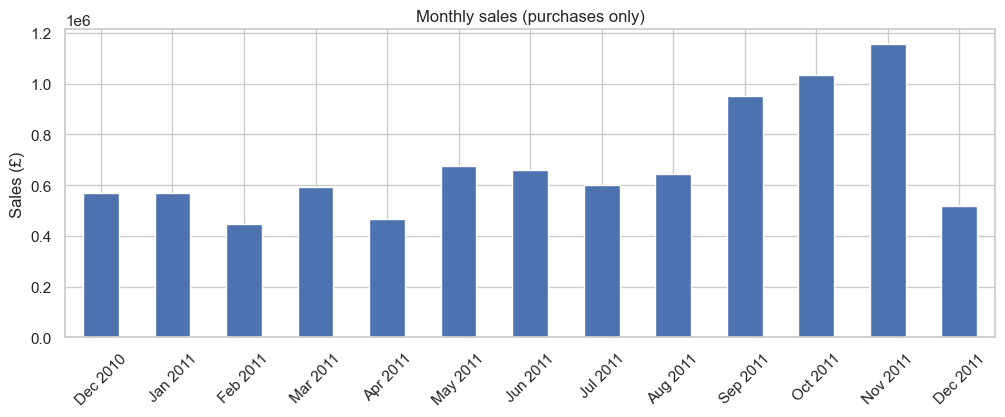

In [5]:
monthly = clean[~clean["IsReturn"]].set_index("InvoiceDate")["Amount"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot.bar(ax=ax)
ax.set_xticklabels([d.strftime("%b %Y") for d in monthly.index], rotation=45)
ax.set(title="Monthly sales (purchases only)", xlabel="", ylabel="Sales (£)")
plt.show()

Sales climb toward the holiday season. December 2011 is low only because the data stops on 9 Dec.

In [6]:
country_share = clean.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False)
print(f"UK share of customers: {country_share['United Kingdom'] / clean['CustomerID'].nunique():.0%}")
country_share.head(10)

UK share of customers: 90%


Country
United Kingdom    3949
Germany             95
France              87
Spain               31
Belgium             25
Switzerland         21
Portugal            19
Italy               15
Finland             12
Austria             11
Name: CustomerID, dtype: int64

## 4. Split time into a feature window and a target window

To avoid leakage, features use **only** data before the cutoff, and the target uses **only** data after it.

| Window | Dates | Used for |
|---|---|---|
| Past | 1 Dec 2010 – 31 Aug 2011 | Features |
| Future | 1 Sep 2011 – 9 Dec 2011 | `Will_Return` target |

In [7]:
CUTOFF = pd.Timestamp("2011-09-01")
START, END = clean["InvoiceDate"].min(), clean["InvoiceDate"].max()

past = clean[clean["InvoiceDate"] < CUTOFF]
future = clean[clean["InvoiceDate"] >= CUTOFF]
past_buys = past[~past["IsReturn"]]

past_days = (CUTOFF - START.normalize()).days
future_days = (END.normalize() - CUTOFF).days + 1
print(f"Past window: {past_days} days, future window: {future_days} days")

Past window: 274 days, future window: 100 days


## 5. Engineer per-customer features

In [8]:
g = past_buys.groupby("CustomerID")
features = pd.DataFrame({
    "Recency": (CUTOFF - g["InvoiceDate"].max()).dt.days,      # days since last purchase
    "Frequency": g["InvoiceNo"].nunique(),                      # number of invoices
    "Monetary": g["Amount"].sum(),                              # total past spending
    "Tenure": (CUTOFF - g["InvoiceDate"].min()).dt.days,        # days since first purchase
    "UniqueProducts": g["StockCode"].nunique(),
    "AvgUnitPrice": g["UnitPrice"].mean(),
    "TotalQuantity": g["Quantity"].sum(),
})
features["AvgBasketValue"] = features["Monetary"] / features["Frequency"]
features["Returns"] = (past[past["IsReturn"]].groupby("CustomerID")["InvoiceNo"].nunique()
                       .reindex(features.index, fill_value=0))
features["IsUK"] = (g["Country"].first() == "United Kingdom").astype(int)

print("Customers with at least one past purchase:", len(features))
features.describe().round(1)

Customers with at least one past purchase: 3317


,Recency,Frequency,Monetary,Tenure,UniqueProducts,AvgUnitPrice,TotalQuantity,AvgBasketValue,Returns,IsUK
count,3317.0,3317.0,3317.0,3317.0,3317.0,3317.0,3317.0,3317.0,3317.0,3317.0
mean,92.1,3.4,1576.0,175.7,49.1,4.2,923.8,399.4,0.7,0.9
std,76.7,5.6,5974.0,77.9,66.2,13.9,3733.9,1435.7,1.7,0.3
min,0.0,1.0,2.9,0.0,1.0,0.1,1.0,2.9,0.0,0.0
25%,27.0,1.0,258.2,117.0,13.0,2.3,128.0,168.2,0.0,1.0
50%,72.0,2.0,552.8,184.0,29.0,3.0,305.0,283.5,0.0,1.0
75%,146.0,4.0,1355.1,257.0,62.0,4.0,767.0,412.6,1.0,1.0
max,273.0,127.0,176355.9,273.0,1190.0,451.4,126731.0,77183.6,29.0,1.0


## 6. Build the target

`Will_Return` is 1 if the customer makes at least one **purchase** (not a return) in the future window, and 0 otherwise.

Only customers with at least one past purchase have features, so customers who first appear after the cutoff are not included.

In [ ]:
future_buyers = future.loc[~future["IsReturn"], "CustomerID"].unique()
data = features.copy()
data["Will_Return"] = data.index.isin(future_buyers).astype(int)

print(f"Customers: {len(data)}, returned: {data['Will_Return'].sum()} ({data['Will_Return'].mean():.0%})")

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
data["Will_Return"].map({0: "Did not return", 1: "Returned"}).value_counts().plot.bar(ax=ax, rot=0)
ax.set(title="Class balance: did the customer buy again (Sep–Dec 2011)?", xlabel="", ylabel="Customers")
plt.show()

The classes are moderately imbalanced: about 59% of customers return and 41% don't. Always guessing "returns" already gives about 59% accuracy, so accuracy alone is misleading. We use a stratified split and focus on F1 and ROC-AUC.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(x=data["Will_Return"], y=np.log1p(data[col]), ax=ax)
    ax.set(title=f"log(1 + {col}) by outcome", xlabel="Will_Return (0 = no, 1 = yes)", ylabel="")
plt.tight_layout()
plt.show()

_TODO after running: takeaway, e.g. do returning customers have lower Recency and higher Frequency/Monetary, and how much do the boxes overlap?_

## 7. Train/test split

Most features are heavily skewed, so we log-transform them (except the `IsUK` flag). Tree models don't need this, but it helps Logistic Regression. The log transform has no fitted parameters, so applying it before the split does not leak information. The split is **stratified** so train and test keep the same return rate.

In [ ]:
FEATURES = list(features.columns)
SKEWED = [c for c in FEATURES if c != "IsUK"]

def prepare(df):
    X = df[FEATURES].copy()
    X[SKEWED] = np.log1p(X[SKEWED])
    return X

X = prepare(data)
y = data["Will_Return"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Return rate - train: {y_train.mean():.1%}, test: {y_test.mean():.1%}")

## 8. Baselines

A model is only useful if it beats simple rules:
1. **Always "returns":** predicts the majority class for everyone (`DummyClassifier`).
2. **Rule of thumb, "bought in the last 90 days":** a common business rule. It is fixed in advance, not fitted, so it uses no test information.

In [ ]:
def scores(name, y_pred, y_score, cv_auc=np.nan):
    return {
        "Model": name,
        "CV ROC-AUC": cv_auc,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    }

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
recency = data.loc[X_test.index, "Recency"]  # raw days, not log
baselines = [
    scores("Baseline: always 'returns'", dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1]),
    scores("Rule: bought in last 90 days", (recency <= 90).astype(int), -recency),
]
pd.DataFrame(baselines).set_index("Model").round(3)

## 9. Train and tune models

Each model is tuned with stratified 5-fold cross-validation on the training set only, scored by ROC-AUC.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__n_estimators": [300], "model__max_depth": [5, 10, None],
                       "model__min_samples_leaf": [5, 20]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {"model__n_estimators": [100, 300], "model__learning_rate": [0.03, 0.1],
                           "model__max_depth": [2, 3], "model__subsample": [0.8]}),
}

searches = {}
for name, (model, grid) in candidates.items():
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
    searches[name] = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    print(f"{name}: CV ROC-AUC = {searches[name].best_score_:.3f}  {searches[name].best_params_}")

## 10. Evaluate on the test set

In [ ]:
def evaluate(name, search):
    proba = search.predict_proba(X_test)[:, 1]
    return scores(name, (proba >= 0.5).astype(int), proba, search.best_score_)

results = pd.DataFrame(baselines + [evaluate(n, s) for n, s in searches.items()]).set_index("Model")
results.round(3)

In [ ]:
best_name = results["CV ROC-AUC"].idxmax()  # baselines have no CV score, so they are skipped
best_model = searches[best_name].best_estimator_
print("Best model (chosen by CV ROC-AUC, not test score):", best_name)

**Reading the results**

_TODO after running: compare each model's F1 and ROC-AUC with the two baselines, say whether the best model clearly beats the 90-day rule, and note any trade-off between precision and recall._

## 11. Inspect the best model

In [ ]:
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No return", "Returns"],
                                        cmap="Blues", ax=axes[0])
axes[0].set(title=f"Confusion matrix ({best_name}, threshold 0.5)")
for name, search in searches.items():
    RocCurveDisplay.from_estimator(search.best_estimator_, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[1].set(title="ROC curves (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

_TODO after running: takeaway, e.g. which error is more common (false positives or false negatives), and how far the ROC curves sit above the random line._

In [ ]:
importance = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                                    random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax)
ax.set(title="Permutation importance (drop in ROC-AUC when a feature is shuffled)", xlabel="Mean drop in ROC-AUC")
plt.show()
importance.sort_values(ascending=False).round(3)

## 12. Error analysis: who does the model get wrong?

We compare the typical (median) customer in each outcome group, using the raw feature values.

In [ ]:
test_view = data.loc[X_test.index, FEATURES].assign(actual=y_test, predicted=pred)
test_view["outcome"] = np.select(
    [(test_view["actual"] == 1) & (test_view["predicted"] == 1),
     (test_view["actual"] == 0) & (test_view["predicted"] == 0),
     (test_view["actual"] == 0) & (test_view["predicted"] == 1)],
    ["Correct: returns", "Correct: no return", "False positive (predicted return)"],
    default="False negative (missed a return)",
)
test_view.groupby("outcome")[["Recency", "Frequency", "Monetary", "Tenure"]].median().assign(
    customers=test_view["outcome"].value_counts()).round(0)

_TODO after running: describe the typical false positive and false negative customer (e.g. recent one-time buyers vs older frequent buyers)._

In [ ]:
# Business use: the 20% of customers with the lowest predicted chance of returning are the retention target
at_risk = proba <= np.quantile(proba, 0.2)
print(f"Customers flagged as at-risk: {at_risk.sum()}")
print(f"Share that really did not return: {(y_test[at_risk] == 0).mean():.0%}")
print(f"Non-return rate across all test customers: {(y_test == 0).mean():.0%}")

## 13. Results vs success metrics

In [ ]:
best = results.loc[best_name]
base = results.loc["Baseline: always 'returns'"]
rule = results.loc["Rule: bought in last 90 days"]
pd.DataFrame([
    {"Metric": "ROC-AUC", "Target": "≥ 0.70", "Result": f"{best['ROC-AUC']:.3f}",
     "Met?": "Yes" if best["ROC-AUC"] >= 0.70 else "No"},
    {"Metric": "F1", "Target": "Beat the baselines", "Result": f"{best['F1']:.3f}",
     "Met?": f"always-returns {base['F1']:.3f}, 90-day rule {rule['F1']:.3f}"},
    {"Metric": "Accuracy", "Target": "Beat majority class", "Result": f"{best['Accuracy']:.3f}",
     "Met?": "Yes" if best["Accuracy"] > base["Accuracy"] else "No"},
    {"Metric": "Beats 90-day rule (ROC-AUC)", "Target": "Model > rule", "Result": f"{best['ROC-AUC']:.3f} vs {rule['ROC-AUC']:.3f}",
     "Met?": "Yes" if best["ROC-AUC"] > rule["ROC-AUC"] else "No"},
])

## 14. Assumptions, limitations, and next steps

**Assumptions**
- Past buying behavior predicts whether a customer comes back.
- The September–December period is representative. It includes the holiday season, which may raise the return rate.
- Customers are identified correctly by `CustomerID`.

**Limitations**
- 25% of rows (135,080) have no `CustomerID` and were dropped.
- Duplicates and zero or negative prices were removed, and cancelled invoices were treated as returns.
- A customer counts as "returned" after a single purchase of any size, so a £3 order and a £3,000 order look the same.
- About 90% of customers are from the UK, so results may not generalize to other countries.
- The data covers only one year (2010–2011), so long-term trends and repeated seasons can't be captured.
- The 0.5 decision threshold is a default. The right threshold depends on the cost of a missed lapse vs a wasted discount.

**Suggested next steps**
- Choose the decision threshold with cross-validation on the training set, based on campaign costs.
- Check stability over time: repeat the experiment with an earlier cutoff (e.g. 1 Jun 2011) and see if the model still beats the 90-day rule.
- Add product-category and seasonality features, and combine with a spend model for a full CLV estimate.

**What this model should not be used for**
- Deciding on its own to drop or deny service to individual customers. It gives a probability, not a certainty.
- Customers outside the UK-heavy, 2010–2011 customer base, or brand-new customers with no purchase history.
- Predicting *how much* a customer will spend. It only predicts *whether* they buy again.